# 03 — Explainability: Loan Default Prediction

**Purpose:** Explain global logistic-regression drivers and one final-test applicant near the frozen operating threshold. No retraining or threshold tuning is performed. Manual contributions and SHAP are expressed in **log-odds**, not probability percentage points.

**Run from the project:** `notebooks/03_explainability.ipynb`, with `data/loan_applications_cleaned_dataset.csv`, `models/loan_default_model_v1.joblib` and `.json`. Use the model's training version of scikit-learn (1.7.2).

In [1]:
from pathlib import Path
import json, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from scipy.special import expit
from sklearn.model_selection import train_test_split
from IPython.display import display

PROJECT = Path.cwd().resolve()
if PROJECT.name == "notebooks":
    PROJECT = PROJECT.parent
DATA = PROJECT / "data" / "loan_applications_cleaned_dataset.csv"
MODEL = PROJECT / "models" / "loan_default_model_v1.joblib"
META = PROJECT / "models" / "loan_default_model_v1.json"

model = joblib.load(MODEL)
metadata = json.loads(META.read_text(encoding="utf-8"))
threshold = float(metadata["operating_threshold"])
print("Model:", metadata["version"], "Threshold:", threshold)

Model: 1 Threshold: 0.24523310312331778


## 1. Reconstruct the untouched final test set

In [2]:
df = pd.read_csv(DATA)
X = df.drop(columns="defaulted")
y = df["defaulted"].astype(int)
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print("Development:", len(X_dev), "Final test:", len(X_test))

Development: 20000 Final test: 5000


## 2. Global coefficients on transformed features

Numerical columns are median-imputed and standardized; categorical columns are one-hot encoded. Each coefficient measures the log-odds change for a one-unit change in that **transformed** feature, holding the other transformed features fixed. Coefficient magnitudes across different encodings are not directly comparable measures of causal importance. One-hot coefficients must be interpreted with care because categories are mutually exclusive.

,transformed_feature,coefficient_log_odds,abs_coefficient
2,num__credit_score,-1.0211,1.0211
6,num__debt_to_income_pct,0.7817,0.7817
7,num__previous_defaults,0.5450,0.5450
12,cat__home_ownership_mortgage,-0.4937,0.4937
13,cat__home_ownership_own,-0.4871,0.4871
8,cat__employment_status_employed,-0.4602,0.4602
9,cat__employment_status_retired,-0.4144,0.4144
10,cat__employment_status_self-employed,-0.3299,0.3299
5,num__interest_rate,0.2065,0.2065
0,num__applicant_age,-0.1940,0.1940


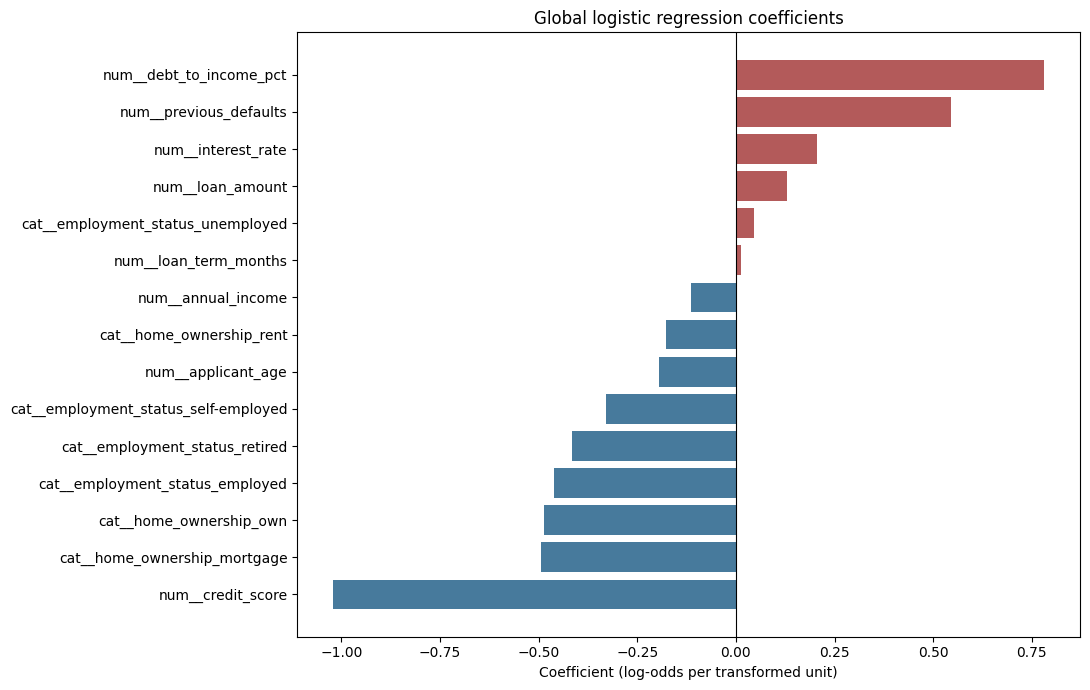

In [3]:
preprocessor = model.named_steps["preprocessor"]
classifier = model.named_steps["classifier"]
feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]
coefficient_table = pd.DataFrame({"transformed_feature": feature_names, "coefficient_log_odds": coefficients})
coefficient_table["abs_coefficient"] = coefficient_table.coefficient_log_odds.abs()
display(coefficient_table.sort_values("abs_coefficient", ascending=False).round(4))
chart = coefficient_table.sort_values("coefficient_log_odds")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(chart.transformed_feature, chart.coefficient_log_odds, color=np.where(chart.coefficient_log_odds >= 0, "#b35a5a", "#477a9c"))
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Coefficient (log-odds per transformed unit)", title="Global logistic regression coefficients")
fig.tight_layout()
plt.show()

## 3. Find the final-test applicant closest to the operating threshold

In [4]:
test_probability = model.predict_proba(X_test)[:, 1]
position = int(np.argmin(np.abs(test_probability - threshold)))
applicant = X_test.iloc[[position]]
applicant_id = X_test.index[position]
probability = float(test_probability[position])
print(f"Final-test row index: {applicant_id}; predicted probability: {probability:.9f}; threshold: {threshold:.9f}")
print("Decision:", "high-risk / manual review" if probability >= threshold else "low-risk / no flag")
display(applicant.T.rename(columns={applicant_id: "applicant_value"}))

Final-test row index: 20016; predicted probability: 0.245353532; threshold: 0.245233103
Decision: high-risk / manual review


,applicant_value
applicant_age,65
employment_status,retired
annual_income,65100.0
credit_score,640.0
loan_amount,22400.0
loan_term_months,24
interest_rate,7.14
debt_to_income_pct,48.8
home_ownership,mortgage
previous_defaults,0


## 4. Manual local explanation: coefficient × transformed value

The classifier logit is **intercept + sum of contributions**. Positive contributions push the log-odds above the intercept-only baseline; negative contributions pull them below it. These are not differences in probability points.

Intercept: -1.1719306293083014 Sum contributions: 0.04838140488051068
Reconstructed probability: 0.24535353249211728
Top positive contributors:


,feature,transformed_value,coefficient,contribution_log_odds
6,num__debt_to_income_pct,1.197419,0.781686,0.936006
2,num__credit_score,-0.478019,-1.021130,0.488120
3,num__loan_amount,1.164539,0.129588,0.150910


Top negative contributors:


,feature,transformed_value,coefficient,contribution_log_odds
12,cat__home_ownership_mortgage,1.000000,-0.493734,-0.493734
9,cat__employment_status_retired,1.000000,-0.414416,-0.414416
0,num__applicant_age,1.432773,-0.194044,-0.278022


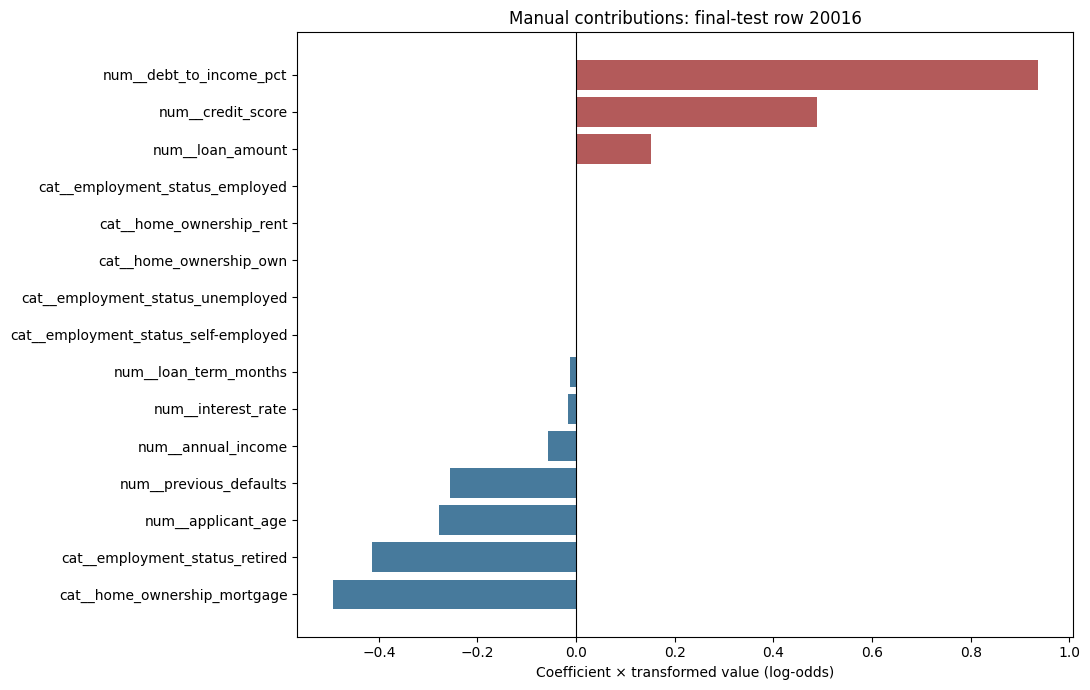

In [5]:
transformed = np.asarray(preprocessor.transform(applicant)).reshape(-1)
local_contributions = coefficients * transformed
local_table = pd.DataFrame({"feature": feature_names, "transformed_value": transformed, "coefficient": coefficients, "contribution_log_odds": local_contributions})
logit_manual = float(classifier.intercept_[0] + local_contributions.sum())
reconstructed_probability = float(expit(logit_manual))
assert np.isclose(reconstructed_probability, probability, atol=1e-10)
print("Intercept:", classifier.intercept_[0], "Sum contributions:", local_contributions.sum())
print("Reconstructed probability:", reconstructed_probability)
print("Top positive contributors:")
display(local_table[local_table.contribution_log_odds > 0].nlargest(3, "contribution_log_odds"))
print("Top negative contributors:")
display(local_table[local_table.contribution_log_odds < 0].nsmallest(3, "contribution_log_odds"))
ordered = local_table.sort_values("contribution_log_odds")
fig, ax = plt.subplots(figsize=(11, 7))
ax.barh(ordered.feature, ordered.contribution_log_odds, color=np.where(ordered.contribution_log_odds >= 0, "#b35a5a", "#477a9c"))
ax.axvline(0, color="black", linewidth=.8)
ax.set(xlabel="Coefficient × transformed value (log-odds)", title=f"Manual contributions: final-test row {applicant_id}")
fig.tight_layout()
plt.show()

## 5. SHAP local explanation

The SHAP reference uses **200 development-set rows**, sampled reproducibly, never final-test rows. It is transformed with the fitted preprocessor. SHAP explains deviations from the average model log-odds over that reference, whereas the manual method explains deviations from the model intercept. Therefore their per-feature values need not match. Both must reconstruct the same logit.

SHAP expected log-odds: -1.8231062966151952
SHAP reconstructed probability: 0.2453535324921173
SHAP top positive:


,feature,shap_log_odds
6,num__debt_to_income_pct,0.834851
2,num__credit_score,0.536274
8,cat__employment_status_employed,0.271515


SHAP top negative:


,feature,shap_log_odds
9,cat__employment_status_retired,-0.358470
12,cat__home_ownership_mortgage,-0.320927
7,num__previous_defaults,-0.299274


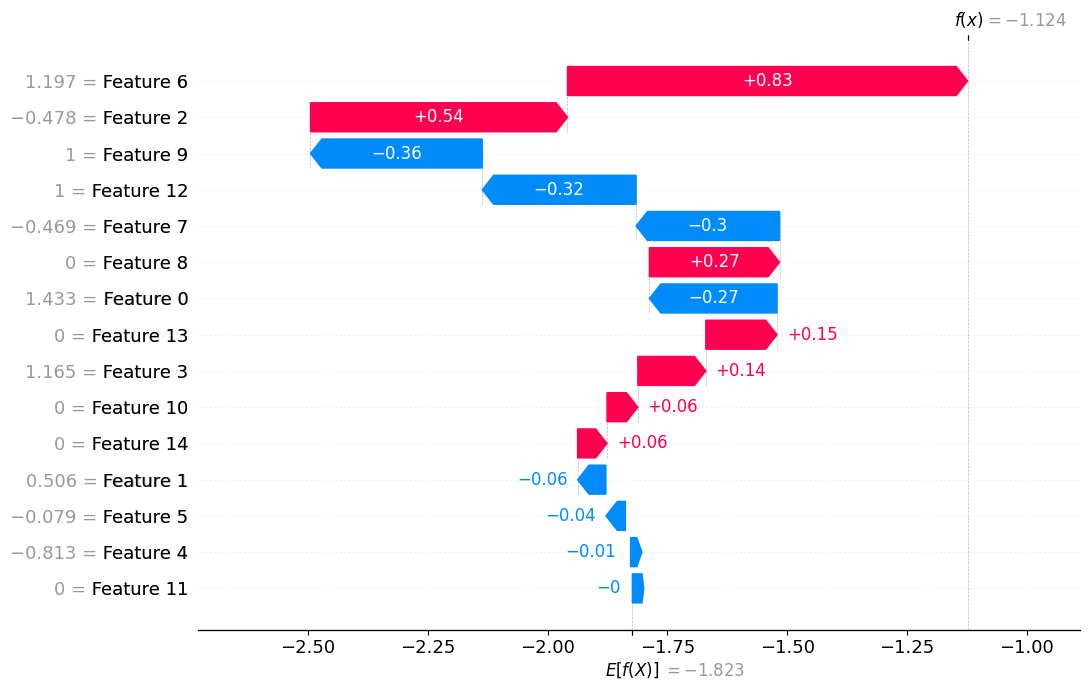

In [6]:
background_raw = X_dev.sample(n=min(200, len(X_dev)), random_state=42)
background = np.asarray(preprocessor.transform(background_raw))
masker = shap.maskers.Independent(background, max_samples=len(background))
explainer = shap.LinearExplainer(classifier, masker)
explanation = explainer(np.asarray(preprocessor.transform(applicant)))
shap_values = explanation.values[0]
shap_base = float(explanation.base_values[0])
shap_probability = float(expit(shap_base + shap_values.sum()))

print("SHAP expected log-odds:", shap_base)
print("SHAP reconstructed probability:", shap_probability)
shap_table = pd.DataFrame({"feature": feature_names, "shap_log_odds": shap_values})
print("SHAP top positive:")
display(shap_table[shap_table.shap_log_odds > 0].nlargest(3, "shap_log_odds"))
print("SHAP top negative:")
display(shap_table[shap_table.shap_log_odds < 0].nsmallest(3, "shap_log_odds"))
shap.plots.waterfall(explanation[0], max_display=15, show=False)
plt.gcf().set_size_inches(11, 7)
plt.tight_layout()
plt.show()

## 6. Interpretation and limitations

- **Global:** The coefficient chart describes associations learned by the fitted logistic regression after scaling and encoding. Positive values increase modeled default log-odds; negative values decrease them.
- **Local:** The manual contribution table answers which transformed inputs move this applicant's score relative to the intercept. SHAP instead compares the applicant with the selected development-set reference.
- **Limitations:** These explanations describe the model, **not the applicant's actual financial circumstances or future actions**. They are associations, not causes. Neither changing an input nor receiving a high-risk label guarantees any real-world outcome. The Independent masker can evaluate unrealistic combinations of mutually exclusive one-hot categories; the SHAP values should be read as model-attribution summaries, not causal effects.

**Operational caution:** A loan officer should use these results as decision support, subject to policy, fairness review, and applicable lending requirements—not as a standalone adverse-action explanation.

## 7. Additional analysis — Permutation Feature Importance vs. coefficients and SHAP

For personal purpose I decided to add this **optional comparison** supplements to the required explanations. Permutation importance measures the change in **ROC-AUC** after independently shuffling each **original input column** in the untouched final test set. It uses the complete fitted pipeline, so imputation, scaling and one-hot encoding remain unchanged. Five repetitions estimate the variability due to shuffling. **No refitting or threshold tuning** is performed.

For comparison, we also calculate global mean absolute SHAP values over a reproducible 500-row final-test sample using the **development-set SHAP background** established above. We sum SHAP values for one-hot columns belonging to the same original categorical field *per applicant* before taking their mean absolute values. Coefficient rankings are included as context using the maximum absolute coefficient in each original field; they are **not** directly comparable in magnitude to permutation or SHAP because they use different units. Correlated features can share predictive information, reducing permutation importance, and shuffling may produce unrealistic combinations.

Baseline final-test ROC-AUC: 0.85034


,original_feature,permutation_auc_drop,permutation_std
3,credit_score,0.15396,0.00796
7,debt_to_income_pct,0.09082,0.00439
9,previous_defaults,0.04028,0.00341
6,interest_rate,0.00619,0.00147
1,employment_status,0.00327,0.00101
0,applicant_age,0.00303,0.00080
4,loan_amount,0.00266,0.00039
8,home_ownership,0.00229,0.00092
2,annual_income,0.00148,0.00063
5,loan_term_months,-0.00004,0.00005


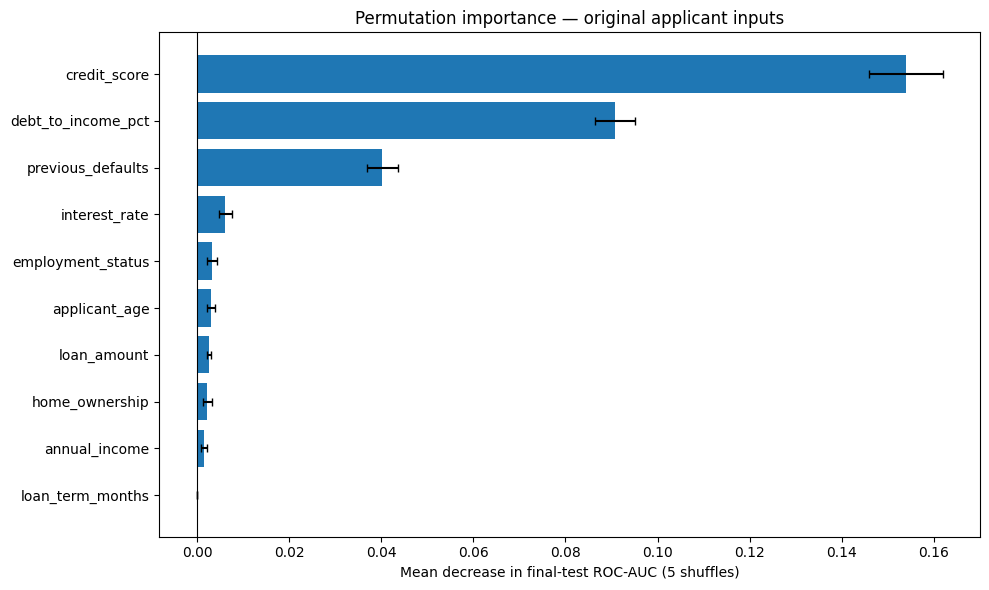

In [7]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

baseline_auc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])
perm_result = permutation_importance(
    model, X_test, y_test,
    scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=1
)
permutation_table = pd.DataFrame({
    "original_feature": X_test.columns,
    "permutation_auc_drop": perm_result.importances_mean,
    "permutation_std": perm_result.importances_std,
}).sort_values("permutation_auc_drop", ascending=False)
print(f"Baseline final-test ROC-AUC: {baseline_auc:.5f}")
display(permutation_table.round(5))

fig, ax = plt.subplots(figsize=(10, 6))
plot_table = permutation_table.sort_values("permutation_auc_drop")
ax.barh(plot_table.original_feature, plot_table.permutation_auc_drop,
        xerr=plot_table.permutation_std, capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Mean decrease in final-test ROC-AUC (5 shuffles)",
       title="Permutation importance — original applicant inputs")
fig.tight_layout()
plt.show()

Feature rankings (different metrics and units; do not compare magnitudes directly):


,permutation_auc_drop,permutation_std,mean_abs_shap_log_odds,abs_coefficient,permutation_auc_drop_rank,mean_abs_shap_log_odds_rank,abs_coefficient_rank
original_feature,,,,,,,
credit_score,0.15396,0.00796,0.80312,1.02113,1,1,1
debt_to_income_pct,0.09082,0.00439,0.66690,0.78169,2,2,2
previous_defaults,0.04028,0.00341,0.42031,0.54497,3,3,3
interest_rate,0.00619,0.00147,0.16371,0.20649,4,5,6
employment_status,0.00327,0.00101,0.09694,0.46020,5,7,5
applicant_age,0.00303,0.00080,0.16648,0.19404,6,4,7
loan_amount,0.00266,0.00039,0.09544,0.12959,7,8,8
home_ownership,0.00229,0.00092,0.14015,0.49373,8,6,4
annual_income,0.00148,0.00063,0.08988,0.11316,9,9,9


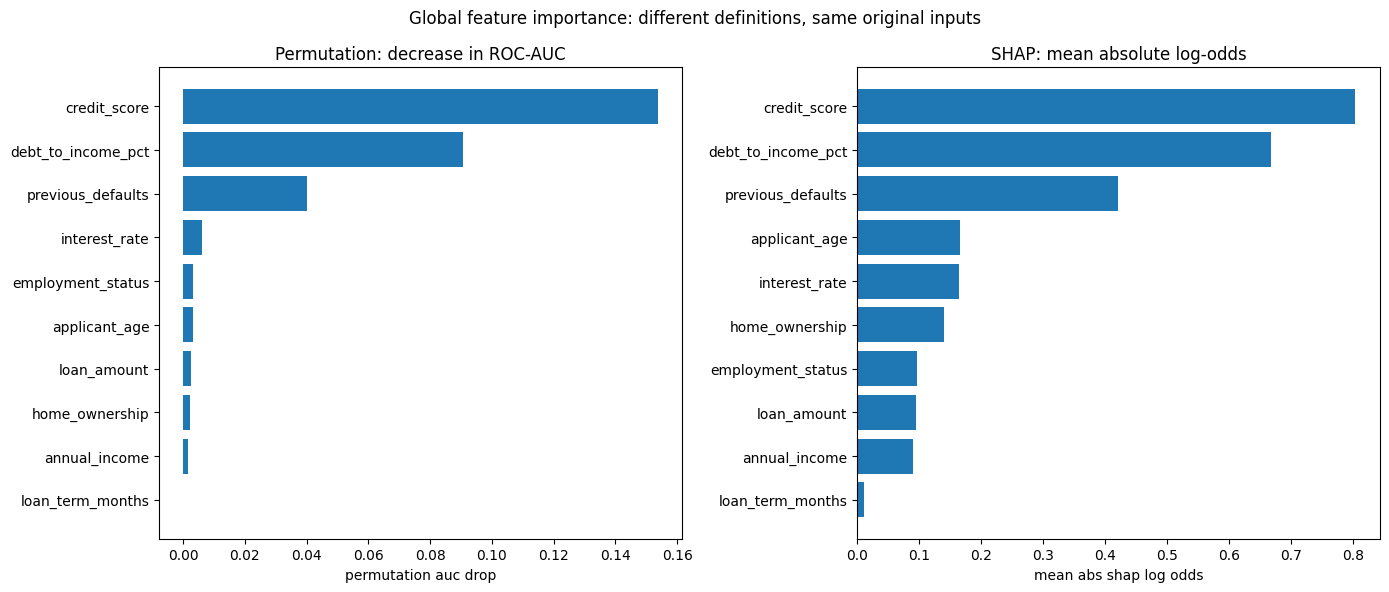

In [8]:
# Map each encoded/transformed column to its original input field.
# The mapping uses fitted ColumnTransformer metadata rather than guessing
# categorical values from transformed column-name prefixes.
original_fields = []
for transformed_name in feature_names:
    suffix = transformed_name.split("__", 1)[-1]
    matches = [field for field in X_test.columns
               if suffix == field or suffix.startswith(field + "_")]
    assert len(matches) == 1, f"Cannot map transformed feature: {transformed_name}"
    original_fields.append(matches[0])
assert len(original_fields) == len(feature_names), "Check original-feature mapping."

# Global SHAP values, using the same development background as Section 5.
shap_sample = X_test.sample(n=min(500, len(X_test)), random_state=42)
shap_matrix = np.asarray(preprocessor.transform(shap_sample))
shap_global = explainer(shap_matrix).values
shap_grouped = pd.DataFrame(shap_global, columns=feature_names)
shap_grouped.columns = original_fields
shap_grouped = shap_grouped.T.groupby(level=0).sum().T
shap_importance = shap_grouped.abs().mean().rename("mean_abs_shap_log_odds")

coefficient_importance = (pd.DataFrame({"original_feature": original_fields,
                                         "abs_coefficient": np.abs(coefficients)})
                          .groupby("original_feature")["abs_coefficient"].max())
comparison = (permutation_table.set_index("original_feature")
              .join(shap_importance).join(coefficient_importance))
for column in ["permutation_auc_drop", "mean_abs_shap_log_odds", "abs_coefficient"]:
    comparison[column + "_rank"] = comparison[column].rank(ascending=False, method="min").astype(int)
comparison = comparison.sort_values("permutation_auc_drop", ascending=False)
print("Feature rankings (different metrics and units; do not compare magnitudes directly):")
display(comparison.round(5))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, column, title in [
    (axes[0], "permutation_auc_drop", "Permutation: decrease in ROC-AUC"),
    (axes[1], "mean_abs_shap_log_odds", "SHAP: mean absolute log-odds")
]:
    subset = comparison.sort_values(column)
    ax.barh(subset.index, subset[column])
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " "))
fig.suptitle("Global feature importance: different definitions, same original inputs")
fig.tight_layout()
plt.show()

### Reading the comparison

- **Coefficient size** describes the fitted log-odds relationship per transformed unit; its sign supplies direction. The summary uses the largest absolute encoded coefficient per original field, which is a descriptive heuristic, not a performance metric.
- **Permutation importance** measures how much ROC-AUC deteriorates when an original feature is shuffled; near-zero or negative values can occur when a field adds little unique predictive information or due to sampling variability.
- **Mean absolute SHAP** describes the average size of each original feature's attribution relative to the development-set background. It does not measure performance loss, and the sign is removed by the absolute value.

**Interpretation:** Compare *rankings*, not numerical magnitudes. Differences are expected because the methods answer different questions. Shuffling one input may break relationships between inputs, and the Independent SHAP masker assumes independent transformed columns. None of these methods establishes causality.